# 15 중간 점검 통합 노트북: 명령어 10개 + "명령 아님" (11개 클래스)

데이터 → 0번 기준 → 기준선 A → 팀 모델 B → 평가 → 결과 표를 이 노트북 하나에서 끝까지 실행합니다. 설정은 지금까지의 실험(06~13)으로 정한 것을 씁니다.

| 번호 | 모델 | 설정 (근거) |
|---|---|---|
| E06 | 0번 기준 | 학습 데이터에서 가장 많은 클래스("명령 아님")만 고름 |
| A | 기준선 A: whisper-base 인코더 고정 + Linear | 30초로 채운 입력의 인코더 출력 앞 50칸(1초) 평균, 마지막 층 (05, E08). Linear는 Adam 1e-3, 배치 512, 30에폭, 검증 매크로 F1 최고 에폭 (07). 시드 3개 |
| B | 팀 모델 B: 로그 멜 CNN 99,051개, 처음부터 학습 | EMA(감쇠 0.999), Adam 1e-3 고정, 배치 256, **30에폭, 마지막 에폭 모델** (12·13, E31). 시드 2개 |

- 데이터: Speech Commands v0.02(CC BY 4.0), 공식 화자 기준 분할. 학습은 명령어 30,769 + "명령 아님" 단어 47,623(공식 학습 목록 전부) + 잡음 구간 1,000 = 79,392개, 검증 9,400개(06 목록 파일). **시험 묶음은 불러오지 않습니다**(설정을 모두 정한 뒤 한 번만 씀).
- 지표: 매크로 F1(주 지표), 정확도, 오작동률(들은 단어·잡음), 놓침률, 명령 혼동률. 검증의 60.6%가 "명령 아님"이라 정확도만으로는 판단하지 않습니다.
- 저장: 팀 모델 B 체크포인트와 검증 예측(A, B)을 `CACHE_DIR`에 저장합니다. 오류 분석(틀린 녹음 듣기)과 데모에 씁니다.
- Colab: 런타임 유형 T4 GPU → 모두 실행. `USE_DRIVE = True`면 10·11에서 Drive에 저장한 로그 멜과 Whisper 특징을 다시 써서 특징 뽑기(약 56분)를 건너뜁니다. 저장된 것이 없으면 새로 뽑습니다.
- 예상 시간(저장된 특징 사용 시): 데이터 받기 약 20초 + B 학습 30에폭 × 2 시드(에폭당 약 8초) ≈ 10분 안팎(08·13 실측 기반 어림).
- `SMOKE = True`는 끝까지 도는지만 확인합니다(숫자를 쓰지 않음).

In [13]:
# 셀 1. 설정과 버전
import os, sys, time, random, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio
import soundfile as sf
import transformers
from transformers import WhisperProcessor, WhisperModel
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
import matplotlib.pyplot as plt

SMOKE = False                  # True: 클래스·단어마다 몇 개만, 짧게 (결과 숫자는 쓰지 않음)
USE_DRIVE = False              # True: Colab에서 Google Drive를 연결해 저장한 특징을 다시 씀
SEEDS_A = [0, 1, 2]            # 기준선 A (Linear, 시드 사이 차이가 작음: E17 ± 0.0005)
SEEDS_B = [0, 1]               # 팀 모델 B
DATA_ROOT = "data"
CSV = "splits_11class.csv"
CSV_URL = "https://raw.githubusercontent.com/yuchanghun/DL_26_02_Team2/main/splits_11class.csv"
CACHE_DIR = "cache"
SR = 16000
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
UNSEEN = ["backward", "follow", "forward", "learn", "visual"]
OTHER = "other"
LABELS = COMMANDS + [OTHER]
K = len(LABELS)
WHISPER = "openai/whisper-base"
N_KEEP = 50                    # Whisper 인코더 1칸 = 20 ms → 앞 50칸 = 1초
LIN_EPOCHS, LIN_LR, LIN_BATCH = 30, 1e-3, 512
B_EPOCHS, B_LR, B_BATCH, EMA_DECAY = 30, 1e-3, 256, 0.999
B_CHANNELS = [16, 32, 64, 128]

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/DL_T02_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
DTYPE = torch.float16 if AMP else torch.float32
if SMOKE:
    LIN_EPOCHS, B_EPOCHS = 2, 3
    SEEDS_A, SEEDS_B = [0], [0]
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__,
      "| transformers", transformers.__version__, "| pandas", pd.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if AMP else "GPU 없음 → CPU", "| SMOKE", SMOKE, "| 저장 위치", CACHE_DIR)
RESULTS = []

python 3.13.16 | torch 2.11.0+cu130 | torchaudio 2.11.0+cu130 | transformers 5.20.2 | pandas 2.3.3
device: cuda | Tesla T4 | SMOKE False | 저장 위치 cache


In [14]:
# 셀 2. 데이터: 내려받기, 목록 파일(06), 학습 데이터("명령 아님" 단어는 공식 학습 목록 전부, 08과 같은 순서), 검사
os.makedirs(DATA_ROOT, exist_ok=True)
sc = torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset="training")    # 공식 학습 목록 (검증·시험 목록 제외)
BASE_DIR = os.path.dirname(sc._path)
if not os.path.exists(CSV):
    urllib.request.urlretrieve(CSV_URL, CSV)
table = pd.read_csv(CSV)
table = table[table.split.isin(["train", "val"])].reset_index(drop=True)      # 시험 묶음은 불러오지 않음
base_train = table[table.split == "train"]

rows = []
for i in range(len(sc)):
    path, _, word, spk, _ = sc.get_metadata(i)
    if word in COMMANDS or word in UNSEEN:
        continue
    rows.append({"split": "train", "path": path.replace("\\", "/"), "word": word, "speaker": spk,
                 "label": OTHER, "group": "seen_other", "start": 0, "gain": 1.0})
pool = pd.DataFrame(rows)
used = set(base_train[base_train.group == "seen_other"].path)
assert pool.word.nunique() == 20 and used <= set(pool.path)
rng = np.random.default_rng(0)
pool["first"] = ~pool.path.isin(used)                        # 08과 같은 순서 (저장된 로그 멜·Whisper 특징과 행이 맞게)
pool["rnd"] = rng.random(len(pool))
pool = pool.sort_values(["word", "first", "rnd"]).drop(columns=["first", "rnd"])
pool["rank"] = pool.groupby("word").cumcount()
rest = base_train[base_train.group != "seen_other"].assign(rank=-1)
if SMOKE:
    rest = rest.groupby("label").head(10)
    pool = pool[pool["rank"] < 20]
train_all = pd.concat([rest, pool], ignore_index=True)
val = table[table.split == "val"].reset_index(drop=True)
if SMOKE:
    val = val.groupby(["label", "group"], group_keys=False).sample(frac=1.0, random_state=0)
    val = val.groupby(["label", "group"]).head(10).reset_index(drop=True)

L2I = {l: i for i, l in enumerate(LABELS)}
Y_ALL = torch.tensor(train_all.label.map(L2I).values)
Y_VAL = torch.tensor(val.label.map(L2I).values)
GROUP_VAL = val.group.values

# 검사: 학습·검증 화자 겹침 없음(단어 녹음), 처음 듣는 단어 5개는 학습·검증에 없음
spk_tr = set(train_all[train_all.group != "noise"].speaker); spk_va = set(val[val.group != "noise"].speaker)
assert not (spk_tr & spk_va), "학습·검증 화자가 겹침"
assert not (set(train_all.word) | set(val.word)) & set(UNSEEN), "처음 듣는 단어가 학습·검증에 있음"
print(f"학습 {len(train_all):,}개 / 검증 {len(val):,}개 | 학습·검증 화자 겹침 0명, 처음 듣는 단어 없음 확인")
cnt = pd.DataFrame({"학습": train_all.groupby("label").size(), "검증": val.groupby("label").size()}).loc[LABELS]
print(cnt.T.to_string())
print("검증 구성:", val.groupby("group").size().to_dict(), f"| 검증 중 '명령 아님' {(Y_VAL == L2I[OTHER]).float().mean():.1%}")

학습 79,392개 / 검증 9,400개 | 학습·검증 화자 겹침 0명, 처음 듣는 단어 없음 확인
label   yes    no    up  down  left  right    on   off  stop    go  other
학습     3228  3130  2948  3134  3037   3019  3086  2970  3111  3106  48623
검증      397   406   350   377   352    363   363   373   350   372   5697
검증 구성: {'command': 3703, 'noise': 117, 'seen_other': 5580} | 검증 중 '명령 아님' 60.6%


In [15]:
# 셀 3. 소리 읽기와 저장 도구 (06과 같은 규칙: 잡음은 start부터 1초를 잘라 gain을 곱함, 단어는 1초로 맞춤)
def load_row(r):
    if r.group == "noise":
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32", start=int(r.start), frames=SR)
        x = x * float(r.gain)
    else:
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32")
    return np.pad(x, (0, max(0, SR - len(x))))[:SR]

class Rows(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        return load_row(self.df.iloc[i])

def loader(df, batch):
    return torch.utils.data.DataLoader(Rows(df), batch_size=batch, shuffle=False,
                                       num_workers=2 if os.name != "nt" else 0, collate_fn=lambda b: np.stack(b))

def cached(name, fn):
    path = os.path.join(CACHE_DIR, f"{name}{'_smoke' if SMOKE else ''}.pt")
    if os.path.exists(path):
        d = torch.load(path)
        print(f"  {name}: 저장된 것 사용 (처음 계산 {d['sec']:.0f}초)")
        return d
    d = fn()
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save(d, path)
    return d

In [16]:
# 셀 4. 평가 함수와 결과 표
def evaluate(pred, y=None, groups=None):
    y = Y_VAL if y is None else y
    groups = GROUP_VAL if groups is None else groups
    p, t = pred.cpu().numpy(), y.cpu().numpy()
    cm = np.bincount(t * K + p, minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm)
    prec, rec = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    oth = L2I[OTHER]
    is_cmd = t != oth
    r = {"acc": float(tp.sum() / cm.sum()), "f1": float(f1.mean()), "cm": cm, "pred": p,
         "miss": float(np.mean(p[is_cmd] == oth)),
         "confuse": float(np.mean((p[is_cmd] != oth) & (p[is_cmd] != t[is_cmd])))}
    for g in ["seen_other", "noise"]:
        m = groups == g
        r[f"fa_{g}"] = float(np.mean(p[m] != oth)) if m.any() else float("nan")
    return r

def add_result(eid, setting, runs, sec, note=""):
    """runs: 시드마다 evaluate 결과. 평균(시드가 여럿이면 ± 표준편차)을 결과 표에 넣음"""
    d = pd.DataFrame([{k: r[k] for k in ["acc", "f1", "fa_seen_other", "fa_noise", "miss", "confuse"]} for r in runs])
    sd = d.std() if len(d) > 1 else d.mean() * 0
    RESULTS.append({"번호": eid, "설정": setting, "시드 수": len(runs), "정확도": d.acc.mean(), "매크로 F1": d.f1.mean(), "F1 표준편차": sd.f1,
                    "오작동(들은 단어)": d.fa_seen_other.mean(), "오작동(잡음)": d.fa_noise.mean(), "놓침": d.miss.mean(),
                    "명령 혼동": d.confuse.mean(), "시간(초)": sec, "비고": note})
    print(f"{eid}: 정확도 {d.acc.mean():.2%} | 매크로 F1 {d.f1.mean():.4f}" + (f" ± {sd.f1:.4f}" if len(d) > 1 else "") +
          f" | 오작동 들은 단어 {d.fa_seen_other.mean():.2%}, 잡음 {d.fa_noise.mean():.2%} | 놓침 {d.miss.mean():.2%} | 명령 혼동 {d.confuse.mean():.2%}")

# E06 0번 기준: 학습 데이터에서 가장 많은 클래스만 고름
maj = train_all.label.value_counts().idxmax()
add_result("E06", f"0번 기준: 가장 많은 클래스({maj})만 고름", [evaluate(torch.full_like(Y_VAL, L2I[maj]))], 0.0, "학습 없음")

E06: 정확도 60.61% | 매크로 F1 0.0686 | 오작동 들은 단어 0.00%, 잡음 0.00% | 놓침 100.00% | 명령 혼동 0.00%


In [17]:
# 셀 5. 기준선 A: whisper-base 인코더 고정 → 앞 50칸 평균, 마지막 층 → Linear (07·10과 같은 특징, 저장된 것이 있으면 다시 씀)
def whisper_feats(df, name):
    def run():
        fe = WhisperProcessor.from_pretrained(WHISPER).feature_extractor
        whisper = WhisperModel.from_pretrained(WHISPER, torch_dtype=DTYPE).to(device).eval()
        X, t0 = [], time.time()
        with torch.no_grad():
            for x in loader(df, 32):
                f = fe(list(x), sampling_rate=SR, return_tensors="pt").input_features.to(device, DTYPE)
                hs = whisper.encoder(f, output_hidden_states=True).hidden_states[1:]
                X.append(torch.stack([h[:, :N_KEEP].mean(1) for h in hs], 1).half().cpu())   # (B, 6층, 512)
        d = {"X": torch.cat(X), "sec": time.time() - t0}
        print(f"  {name}: {tuple(d['X'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run)

# 07에서 저장한 학습 34,829개(목록 파일 순서) + 10에서 저장한 추가 44,563개를 학습 데이터 순서로 이어 붙임
wtrain = base_train.reset_index(drop=True)
if SMOKE:
    wtrain = wtrain.groupby(["label", "group", "word"]).head(3).reset_index(drop=True)
def keys(df):
    return list(zip(df.path, df.start.astype(int), df.gain.astype(float).round(6)))
d_tr = whisper_feats(wtrain, "whisper15_train" if SMOKE else "whisper_base11_train")
d_va = whisper_feats(val, "whisper15_val" if SMOKE else "whisper_base11_val")
W_IDX = {k: i for i, k in enumerate(keys(wtrain))}
src = [W_IDX.get(k, -1) for k in keys(train_all)]
have = torch.tensor([j >= 0 for j in src])
d_ex = whisper_feats(train_all[~have.numpy()].reset_index(drop=True), "whisper15_extra" if SMOKE else "whisper_base11_extra")
WX_ALL = torch.empty(len(train_all), 512, dtype=torch.float16)
WX_ALL[have] = d_tr["X"][[j for j in src if j >= 0], -1]
WX_ALL[~have] = d_ex["X"][:, -1]
WX_VA = d_va["X"][:, -1]
A_FEAT_SEC = d_tr["sec"] + d_va["sec"] + d_ex["sec"]
print(f"Whisper 마지막 층 특징: 학습 {tuple(WX_ALL.shape)}, 검증 {tuple(WX_VA.shape)} | 특징 뽑기 합계 {A_FEAT_SEC:.0f}초(처음 계산 시간)")

def fit_linear(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    X, Y = WX_ALL.float().to(device), Y_ALL.to(device)
    mu, sd = X.mean(0), X.std(0) + 1e-6
    X, Xva = (X - mu) / sd, (WX_VA.float().to(device) - mu) / sd
    head = nn.Linear(512, K).to(device)
    opt = torch.optim.Adam(head.parameters(), lr=LIN_LR)
    best, t0 = None, time.time()
    for ep in range(LIN_EPOCHS):
        perm = torch.randperm(len(X), device=device)
        for i in range(0, len(X), LIN_BATCH):
            idx = perm[i:i + LIN_BATCH]
            loss = nn.functional.cross_entropy(head(X[idx]), Y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            r = evaluate(head(Xva).argmax(1))
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
    best["sec"] = time.time() - t0
    return best

A_RUNS = [fit_linear(s) for s in SEEDS_A]
print("  시드별 F1:", ", ".join(f"{r['f1']:.4f} ({r['epoch']}에폭)" for r in A_RUNS))
add_result("A", "기준선 A: whisper-base 고정 + Linear(512 → 11), 최고 에폭", A_RUNS, A_FEAT_SEC + sum(r["sec"] for r in A_RUNS),
           f"학습 5,643개 / 인코더 20,590,592개 고정, Linear {np.mean([r['sec'] for r in A_RUNS]):.0f}초")

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

... (7 outputs left out)

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

  whisper_base11_val: (9400, 6, 512) (253초)


Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

  whisper_base11_extra: (44563, 6, 512) (1196초)
Whisper 마지막 층 특징: 학습 (79392, 512), 검증 (9400, 512) | 특징 뽑기 합계 2403초(처음 계산 시간)
  시드별 F1: 0.9766 (16에폭), 0.9767 (24에폭), 0.9763 (24에폭)
A: 정확도 98.43% | 매크로 F1 0.9766 ± 0.0002 | 오작동 들은 단어 0.69%, 잡음 0.00% | 놓침 1.99% | 명령 혼동 0.95%


  spec08_train_pool: 저장된 것 사용 (처음 계산 25초)
  spec11_val: 저장된 것 사용 (처음 계산 3초)
팀 모델 B 파라미터: 99,051
    [B 시드 0] 에폭  5/30 | 학습 손실 0.1910 | 검증 손실 1.2478 | 검증 F1 0.2272 | 41초 경과
    [B 시드 0] 에폭 10/30 | 학습 손실 0.1102 | 검증 손실 0.2508 | 검증 F1 0.8902 | 80초 경과
    [B 시드 0] 에폭 15/30 | 학습 손실 0.0742 | 검증 손실 0.1384 | 검증 F1 0.9402 | 120초 경과
    [B 시드 0] 에폭 20/30 | 학습 손실 0.0520 | 검증 손실 0.1272 | 검증 F1 0.9426 | 160초 경과
    [B 시드 0] 에폭 25/30 | 학습 손실 0.0374 | 검증 손실 0.1290 | 검증 F1 0.9436 | 199초 경과
    [B 시드 0] 에폭 30/30 | 학습 손실 0.0257 | 검증 손실 0.1342 | 검증 F1 0.9427 | 239초 경과
    [B 시드 1] 에폭  5/30 | 학습 손실 0.1985 | 검증 손실 1.9311 | 검증 F1 0.0925 | 40초 경과
    [B 시드 1] 에폭 10/30 | 학습 손실 0.1187 | 검증 손실 0.4840 | 검증 F1 0.7398 | 80초 경과
    [B 시드 1] 에폭 15/30 | 학습 손실 0.0789 | 검증 손실 0.1584 | 검증 F1 0.9299 | 120초 경과
    [B 시드 1] 에폭 20/30 | 학습 손실 0.0544 | 검증 손실 0.1243 | 검증 F1 0.9469 | 159초 경과
    [B 시드 1] 에폭 25/30 | 학습 손실 0.0397 | 검증 손실 0.1263 | 검증 F1 0.9500 | 199초 경과
    [B 시드 1] 에폭 30/30 | 학습 손실 0.0277 | 검증 손실 0.1319 | 검증 F1 0

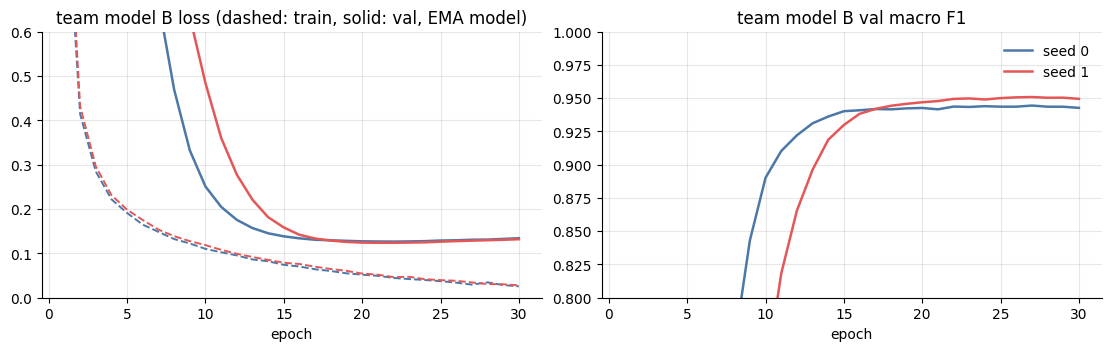

In [18]:
# 셀 6. 팀 모델 B: 로그 멜(64 × 101) → CNN, 처음부터 학습, EMA, 30에폭, 마지막 에폭 모델 (12·13의 E31 설정)
mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=400, hop_length=160, n_mels=64).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)
def spec(df, name):
    def run():
        M, t0 = [], time.time()
        with torch.no_grad():
            for x in loader(df, 256):
                M.append(to_db(mel(torch.from_numpy(x).to(device))).half().cpu())
        d = {"mel": torch.cat(M).unsqueeze(1), "sec": time.time() - t0}
        print(f"  {name}: 로그 멜 {tuple(d['mel'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run)
MEL_ALL = spec(train_all, "spec15_train" if SMOKE else "spec08_train_pool")["mel"]
MEL_VAL = spec(val, "spec15_val" if SMOKE else "spec11_val")["mel"]
assert len(MEL_ALL) == len(train_all) and len(MEL_VAL) == len(val)

class KWSCNN(nn.Module):
    def __init__(self, channels=B_CHANNELS, n_classes=K):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c_in, n_classes)
    def forward(self, x):
        return self.fc(self.pool(self.features(x)).flatten(1))
print("팀 모델 B 파라미터:", f"{sum(p.numel() for p in KWSCNN().parameters()):,}")

def train_b(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    MU, SD = MEL_ALL.float().mean().item(), MEL_ALL.float().std().item()
    Xtr = ((MEL_ALL.float() - MU) / SD).to(device); Ytr = Y_ALL.to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cnn = KWSCNN().to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    ema = AveragedModel(cnn, multi_avg_fn=get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)
    scaler = torch.amp.GradScaler(enabled=AMP)
    hist, t_start = [], time.time()
    for ep in range(B_EPOCHS):
        cnn.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            ema.update_parameters(cnn)
            tot += loss.item() * len(idx)
        ema.eval()
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            logits = torch.cat([ema(Xva[i:i + 1024]) for i in range(0, len(Xva), 1024)]).float()
        r = evaluate(logits.argmax(1))
        hist.append({"epoch": ep + 1, "train_loss": tot / len(Xtr), "val_loss": nn.functional.cross_entropy(logits, Y_VAL.to(device)).item(),
                     "f1": r["f1"], "sec": time.time() - t0})
        if (ep + 1) % 5 == 0 or ep + 1 == B_EPOCHS:
            print(f"    [B 시드 {seed}] 에폭 {ep + 1:2d}/{B_EPOCHS} | 학습 손실 {tot / len(Xtr):.4f} | 검증 손실 {hist[-1]['val_loss']:.4f} | 검증 F1 {r['f1']:.4f} | {time.time() - t_start:.0f}초 경과")
    r["sec"] = time.time() - t_start
    r["hist"] = pd.DataFrame(hist)
    r["prob"] = torch.softmax(logits, 1).cpu().numpy()
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save({"state": ema.module.state_dict(), "mu": MU, "sd": SD, "labels": LABELS, "seed": seed, "epochs": B_EPOCHS},
               os.path.join(CACHE_DIR, f"B_ema30_seed{seed}{'_smoke' if SMOKE else ''}.pt"))
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    return r

B_RUNS = [train_b(s) for s in SEEDS_B]
add_result("B", f"팀 모델 B: 로그 멜 CNN {B_CHANNELS}, 처음부터, EMA, {B_EPOCHS}에폭, 마지막 에폭", B_RUNS, sum(r["sec"] for r in B_RUNS),
           f"파라미터 99,051, 에폭당 {np.mean([r['hist'].sec.mean() for r in B_RUNS]):.1f}초, 체크포인트 저장")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
for k, (r, c) in enumerate(zip(B_RUNS, ["#4C78A8", "#E45756"])):
    h = r["hist"]
    ax[0].plot(h.epoch, h.train_loss, "--", color=c, lw=1.4); ax[0].plot(h.epoch, h.val_loss, "-", color=c, lw=1.8)
    ax[1].plot(h.epoch, h.f1, "-", color=c, lw=1.8, label=f"seed {SEEDS_B[k]}")
ax[0].set_title("team model B loss (dashed: train, solid: val, EMA model)"); ax[0].set_ylim(0, 0.6)
ax[1].set_title("team model B val macro F1"); ax[1].set_ylim(0.8, 1.0); ax[1].legend(frameon=False)
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=.3); a.spines[["top", "right"]].set_visible(False)
os.makedirs("figs", exist_ok=True)
fig.savefig("figs/15_team_model_b_curves.png", dpi=150)
plt.show()

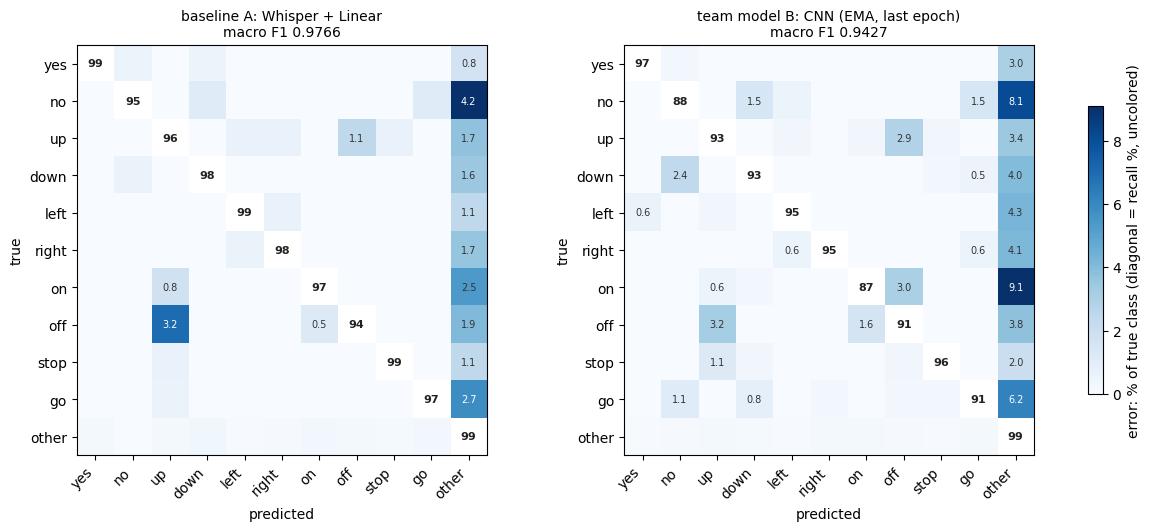

검증 예측 저장: cache/val_predictions_A_B.csv (9,400줄) | A 틀림 147개, B 틀림 349개, 둘 다 틀림 94개


In [19]:
# 셀 7. 혼동 행렬(검증, 시드 0)과 검증 예측 저장 (오류 분석·데모용)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
oth = L2I[OTHER]
for ax, (name, r) in zip(axes, [("baseline A: Whisper + Linear", A_RUNS[0]), ("team model B: CNN (EMA, last epoch)", B_RUNS[0])]):
    cm = r["cm"]; pct = cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100
    E = pct.copy(); np.fill_diagonal(E, np.nan)
    im = ax.imshow(E, cmap="Blues", vmin=0, vmax=max(1, np.nanmax(E)))
    for i in range(K):
        for j in range(K):
            if i == j:
                ax.text(j, i, f"{pct[i, j]:.0f}", ha="center", va="center", fontsize=8, fontweight="bold", color="#222")
            elif pct[i, j] >= 0.5:
                ax.text(j, i, f"{pct[i, j]:.1f}", ha="center", va="center", fontsize=7, color="white" if pct[i, j] > 0.6 * np.nanmax(E) else "#333")
    ax.set_xticks(range(K)); ax.set_xticklabels(LABELS, rotation=45, ha="right"); ax.set_yticks(range(K)); ax.set_yticklabels(LABELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{name}\nmacro F1 {r['f1']:.4f}", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.7, label="error: % of true class (diagonal = recall %, uncolored)")
fig.savefig("figs/15_confusion_matrix.png", dpi=150)
plt.show()

pred_df = val[["path", "word", "group", "label", "start", "gain"]].copy()
pred_df["pred_A"] = [LABELS[i] for i in A_RUNS[0]["pred"]]
pred_df["pred_B"] = [LABELS[i] for i in B_RUNS[0]["pred"]]
pred_df["conf_B"] = B_RUNS[0]["prob"].max(1).round(4)
pred_df["A_correct"] = pred_df.pred_A == pred_df.label
pred_df["B_correct"] = pred_df.pred_B == pred_df.label
pred_path = os.path.join(CACHE_DIR, f"val_predictions_A_B{'_smoke' if SMOKE else ''}.csv")
pred_df.to_csv(pred_path, index=False)
print(f"검증 예측 저장: {pred_path} ({len(pred_df):,}줄) | A 틀림 {(~pred_df.A_correct).sum():,}개, B 틀림 {(~pred_df.B_correct).sum():,}개, 둘 다 틀림 {((~pred_df.A_correct) & (~pred_df.B_correct)).sum():,}개")

In [20]:
# 셀 8. 모든 실험의 결과 표 (검증 묶음 9,400개, 11개 클래스)
res = pd.DataFrame(RESULTS)
pd.set_option("display.width", 230); pd.set_option("display.max_colwidth", 70)
show = res.copy()
for c in ["정확도", "오작동(들은 단어)", "오작동(잡음)", "놓침", "명령 혼동"]:
    show[c] = show[c].map(lambda v: f"{v:.2%}")
show["매크로 F1"] = [f"{f:.4f}" + (f" ± {s:.4f}" if n > 1 else "") for f, s, n in zip(res["매크로 F1"], res["F1 표준편차"], res["시드 수"])]
show["시간(초)"] = show["시간(초)"].map(lambda v: f"{v:.0f}")
print(show.drop(columns=["F1 표준편차"]).to_string(index=False))
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"device {device} | 검증 {len(val):,}개 | A 시드 {SEEDS_A}, B 시드 {SEEDS_B} | 시험 묶음은 쓰지 않음")
print("참고 (이전 결과): A E17 F1 0.9766 ± 0.0002 (10, Colab T4) / B E31 마지막 F1 0.9461 (13, Kaggle T4)")

 번호                                                          설정  시드 수    정확도          매크로 F1 오작동(들은 단어) 오작동(잡음)      놓침 명령 혼동 시간(초)                                        비고
E06                                 0번 기준: 가장 많은 클래스(other)만 고름     1 60.61%          0.0686      0.00%   0.00% 100.00% 0.00%     0                                     학습 없음
  A            기준선 A: whisper-base 고정 + Linear(512 → 11), 최고 에폭     3 98.43% 0.9766 ± 0.0002      0.69%   0.00%   1.99% 0.95%  2416 학습 5,643개 / 인코더 20,590,592개 고정, Linear 4초
  B 팀 모델 B: 로그 멜 CNN [16, 32, 64, 128], 처음부터, EMA, 30에폭, 마지막 에폭     2 96.48% 0.9461 ± 0.0048      1.34%   0.00%   4.55% 2.36%   478           파라미터 99,051, 에폭당 8.0초, 체크포인트 저장
device cuda | 검증 9,400개 | A 시드 [0, 1, 2], B 시드 [0, 1] | 시험 묶음은 쓰지 않음
참고 (이전 결과): A E17 F1 0.9766 ± 0.0002 (10, Colab T4) / B E31 마지막 F1 0.9461 (13, Kaggle T4)
